# 05 – Explanation and Fairness

> **Project notebooks:** [01 Exploration](01_exploration.ipynb) · [02 First model](02_first_model.ipynb) · [03 Tuning and blending](03_tuning_and_blending.ipynb) · [04 Calibration](04_calibration.ipynb) · [05 Explanation and fairness](05_explanation_and_fairness.ipynb)

A lending model makes decisions about people's lives. Two questions come up in every real bank:

1. **"Why was I rejected?"** In many countries a lender must be able to give an applicant the main reasons for a refusal.
2. **"Is it fair?"** Our model uses **age**, and age is a sensitive characteristic. Should a model be allowed to use it? What happens if we remove it?

**Contents**
1. Setup
2. What drives the risk score? (SHAP)
3. The shape of the strongest effects
4. Explaining a single decision
5. Fairness: the role of age
6. What happens without age?
7. Who pays the price?
8. There is no purely technical answer
9. Conclusions

## 1. Setup

In [1]:
import sys
sys.path.append("..")   # the project folder, where src/ lives

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

from src.features import CreditFeatures, TARGET, load

warnings.filterwarnings("ignore", category=FutureWarning)  # hide a harmless seaborn/pandas version notice
sns.set_theme(style="whitegrid", palette="Set2")

df = load("../data/cs-training.csv")
y = df[TARGET].to_numpy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
THRESHOLD = 0.17                                   # from notebook 02
COST_MISSED_DEFAULTER, COST_REJECTED_GOOD = 5_000, 1_000

# Best settings from notebook 03
HGB_SETTINGS = dict(learning_rate=0.02, max_iter=800, max_leaf_nodes=31, min_samples_leaf=20,
                    l2_regularization=1, random_state=42)


def make_xgb():
    return XGBClassifier(learning_rate=0.05, n_estimators=300, max_depth=4, min_child_weight=1, subsample=0.8,
                         colsample_bytree=0.8, eval_metric="auc", tree_method="hist", n_jobs=1, random_state=42)


class FeaturesWithoutAge(CreditFeatures):
    "The same cleaning, but the model never sees the age."
    def transform(self, X):
        return super().transform(X).drop(columns="age")


def blend_cv_probabilities(features):
    hgb = make_pipeline(features, HistGradientBoostingClassifier(**HGB_SETTINGS))
    xgb = make_pipeline(features, make_xgb())
    return (cross_val_predict(hgb, df, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
            + cross_val_predict(xgb, df, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]) / 2


with_age = blend_cv_probabilities(CreditFeatures())
print(f"Blend with age: ROC AUC {roc_auc_score(y, with_age):.4f}")

Blend with age: ROC AUC 0.8664


## 2. What drives the risk score? (SHAP)

As in the earlier projects we use SHAP values, here for the XGBoost half of the blend. For a classification model, XGBoost works on the **log‑odds** scale. The exact unit matters less than the direction: positive SHAP values push the predicted risk **up**, negative ones **down**. We compute them for a random sample of 5,000 borrowers, which is plenty for the charts and takes a second.

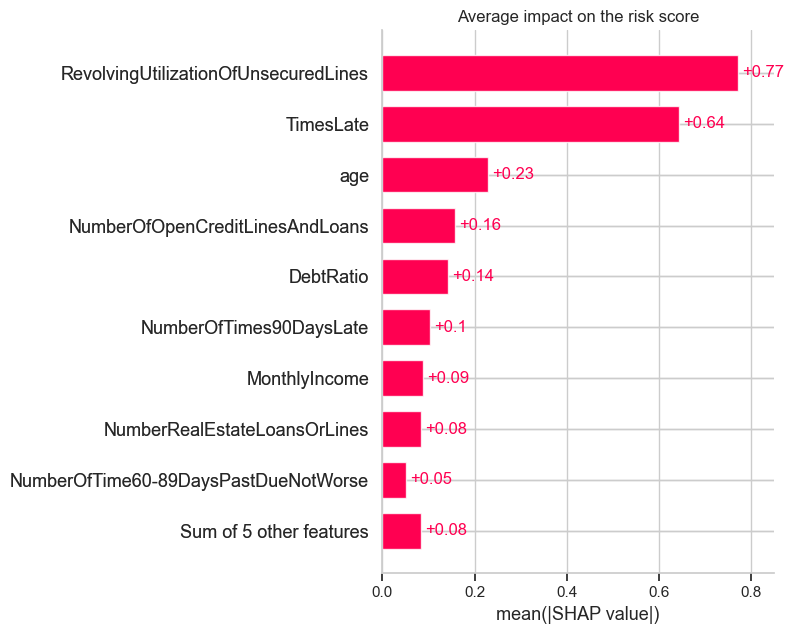

In [2]:
xgb_model = make_pipeline(CreditFeatures(), make_xgb()).fit(df, y)
X_prepared = xgb_model[:-1].transform(df)
sample = X_prepared.sample(5000, random_state=0)

explainer = shap.TreeExplainer(xgb_model[-1])
shap_values = explainer(sample)

shap.plots.bar(shap_values, max_display=10, show=False)
plt.title("Average impact on the risk score")
plt.tight_layout()
plt.savefig("../images/shap_importance.png", dpi=120, bbox_inches="tight")
plt.show()

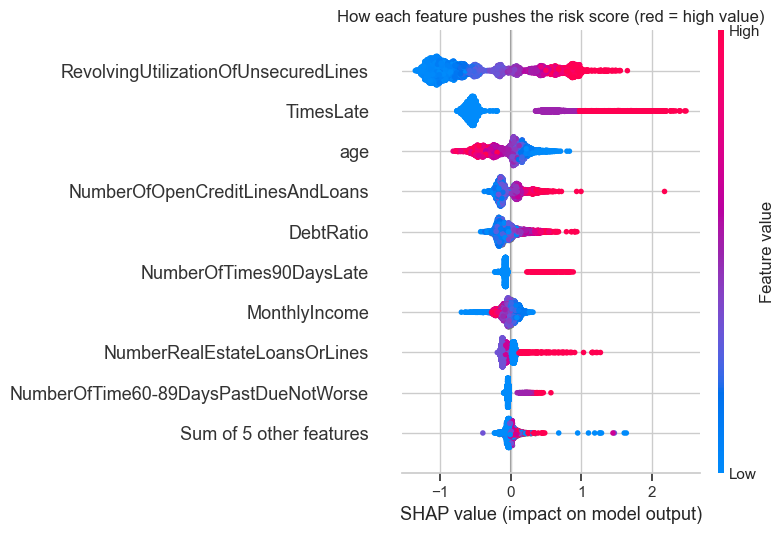

In [3]:
shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.title("How each feature pushes the risk score (red = high value)")
plt.tight_layout()
plt.savefig("../images/shap_beeswarm.png", dpi=120, bbox_inches="tight")
plt.show()

The model's view of a borrower is easy to put into words:

1. **How much of their credit they use** (`RevolvingUtilizationOfUnsecuredLines`) is the strongest factor. High use (red) pushes the risk up.
2. **How often they were late** (`TimesLate`, plus the separate late‑payment columns): every late payment pushes the risk up.
3. **Age**: older borrowers (red) are pushed down, younger ones up.
4. Then the number of open credit lines, the debt ratio and income, with smaller effects.

This matches the exploration in notebook 01 and common sense about credit. A risk model that relies on behaviour (credit use, payment history) rather than on who a person *is* is generally considered more acceptable, which leads to the question about age in section 5.

## 3. The shape of the strongest effects

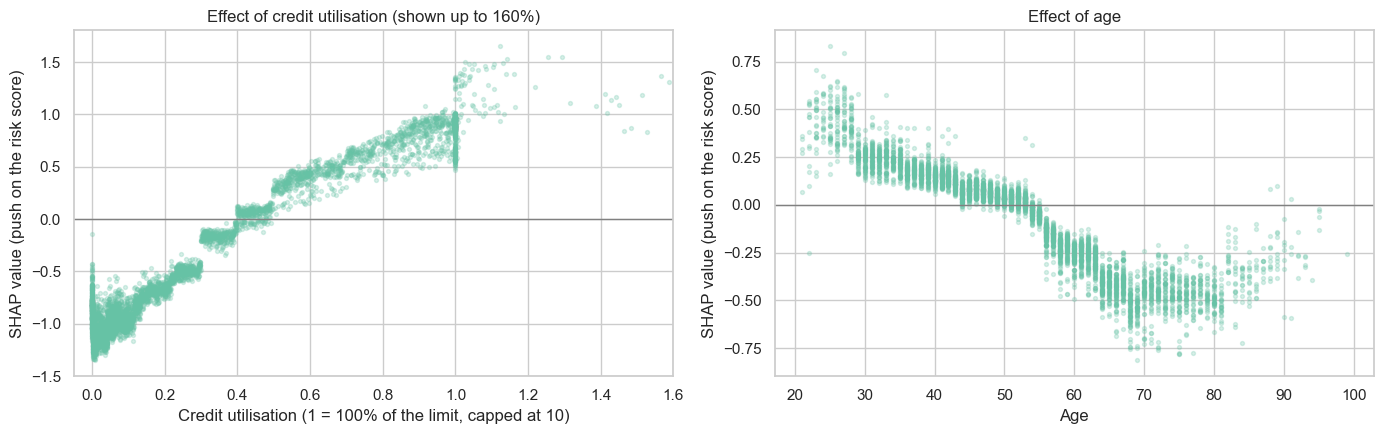

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, feature, xlabel in [(axes[0], "RevolvingUtilizationOfUnsecuredLines", "Credit utilisation (1 = 100% of the limit, capped at 10)"),
                            (axes[1], "age", "Age")]:
    ax.scatter(sample[feature], shap_values[:, feature].values, alpha=0.25, s=8)
    ax.axhline(0, color="grey", linewidth=1)
    ax.set(xlabel=xlabel, ylabel="SHAP value (push on the risk score)")
axes[0].set_xlim(-0.05, 1.6)
axes[0].set_title("Effect of credit utilisation (shown up to 160%)")
axes[1].set_title("Effect of age")
plt.tight_layout()
plt.savefig("../images/shap_effects.png", dpi=120)
plt.show()

**Utilisation:** a strong, almost straight rise. Borrowers who use very little of their credit get a large push towards **lower** risk; the push crosses zero at around 40% use and keeps rising up to the limit, with an extra jump for those **over** their limit. In plain words: *the closer you run to your credit limit, the riskier you look.*

**Age:** the push falls steadily from the twenties to about 65–70, then rises a little again for the oldest borrowers. Younger borrowers are pushed towards higher risk, borrowers in their sixties and seventies towards the lowest.

## 4. Explaining a single decision

A rejected applicant should get the main reasons in plain language. In the United States, for example, lenders must give "adverse action" reasons; many other countries have similar rules. SHAP makes this straightforward: the features with the largest **upward** push are the main reasons for a high risk score.

Applicant 3: predicted risk 34% -> REJECTED
Main reasons for the risk score: late payments in the last two years; payments 90 days or more late; high use of available credit


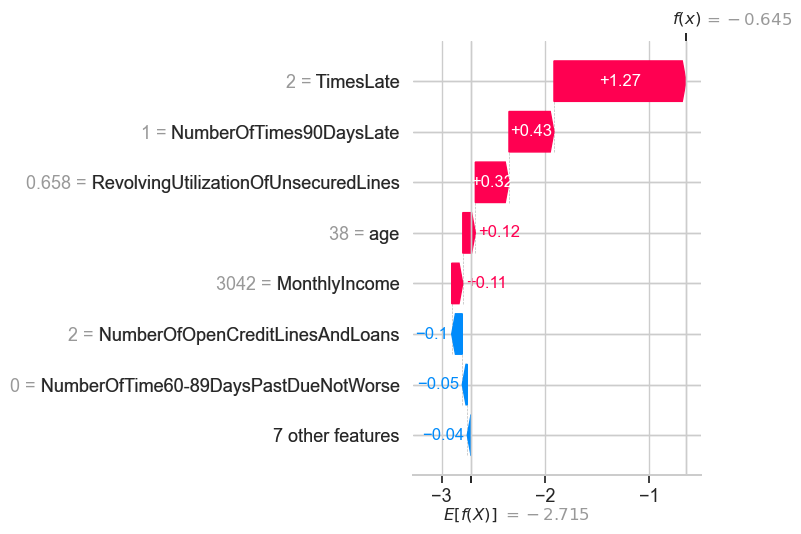

In [5]:
READABLE = {
    "RevolvingUtilizationOfUnsecuredLines": "high use of available credit",
    "TimesLate": "late payments in the last two years",
    "NumberOfTimes90DaysLate": "payments 90 days or more late",
    "NumberOfTime60-89DaysPastDueNotWorse": "payments 60-89 days late",
    "NumberOfTime30-59DaysPastDueNotWorse": "payments 30-59 days late",
    "age": "age",
    "NumberOfOpenCreditLinesAndLoans": "number of open credit lines",
    "DebtRatio": "high debt compared with income",
    "MonthlyIncome": "income",
    "NumberRealEstateLoansOrLines": "number of real estate loans",
    "NumberOfDependents": "number of dependents",
    "MonthlyDebtWhenIncomeUnknown": "monthly debt (income unknown)",
    "NoCreditHistoryCode": "no credit history on file",
    "IncomeMissing": "income not provided",
}

full_probabilities = xgb_model.predict_proba(df)[:, 1]


def explain_applicant(index, n_reasons=3):
    explanation = explainer(X_prepared.loc[[index]])[0]
    pushes = pd.Series(explanation.values, index=X_prepared.columns).sort_values(ascending=False)
    reasons = [READABLE[f] for f in pushes.index[:n_reasons] if pushes[f] > 0]
    decision = "REJECTED" if full_probabilities[index] >= THRESHOLD else "approved"
    print(f"Applicant {df.loc[index, 'Id']}: predicted risk {full_probabilities[index]:.0%} -> {decision}")
    print("Main reasons for the risk score: " + "; ".join(reasons))
    shap.plots.waterfall(explanation, max_display=8, show=False)
    plt.tight_layout()
    plt.show()


example = df.index[(full_probabilities > 0.25) & (full_probabilities < 0.35)][0]
explain_applicant(example)

This applicant gets a risk score of 34%, twice the 17% threshold, so the loan is refused. Reading the chart from the bottom (the average borrower) to the top (this applicant):

- **Two late payments** in the last two years push the risk up the most,
- **one of them 90 days or more late** adds more,
- and using **66% of the available credit** adds a little more.
- Age (38) and income play only a small role.

The printed sentence is what the applicant could be told: *"Main reasons: late payments in the last two years; payments 90 days or more late; high use of available credit."* These reasons are specific, true to the model, and something the applicant can act on.

(The explanation uses the XGBoost half of the blend, trained on all borrowers. In a real system the explanation must always come from the exact model that made the decision.)

## 5. Fairness: the role of age

Age is one of the model's three strongest factors. But is it acceptable to give someone a worse decision **because they are young**?

Rules differ between countries, and this is not legal advice, but two examples show that the question is real:

- In the **United States**, the Equal Credit Opportunity Act generally forbids discrimination by age. A statistically sound scoring system may use age, but not in a way that counts against applicants aged 62 or older.
- In the **European Union**, credit scoring of people is classified as a **high‑risk** use of AI under the AI Act, with requirements for transparency and for checking discrimination.

So a bank has to look carefully. First: how differently does our model treat the age groups, at the 17% threshold?

In [6]:
age_group = pd.cut(df["age"], [17, 30, 40, 50, 60, 70, 120], labels=["18-30", "31-40", "41-50", "51-60", "61-70", "71+"])


def by_age(probabilities):
    frame = pd.DataFrame({"group": age_group, "defaulted": y, "predicted": probabilities,
                          "rejected": probabilities >= THRESHOLD})
    return frame.groupby("group", observed=True).apply(lambda g: pd.Series({
        "borrowers": len(g),
        "actual default rate": g["defaulted"].mean(),
        "average predicted risk": g["predicted"].mean(),
        "rejected": g["rejected"].mean(),
        "good borrowers rejected": g.loc[g["defaulted"] == 0, "rejected"].mean(),
        "defaulters caught": g.loc[g["defaulted"] == 1, "rejected"].mean(),
    }))


percent = {c: "{:.1%}" for c in ["actual default rate", "average predicted risk", "rejected",
                                 "good borrowers rejected", "defaulters caught"]}
with_age_table = by_age(with_age)
with_age_table.style.format({"borrowers": "{:,.0f}", **percent})

,borrowers,actual default rate,average predicted risk,rejected,good borrowers rejected,defaulters caught
group,,,,,,
18-30,"10,757",11.6%,11.5%,20.3%,14.8%,62.9%
31-40,"24,339",9.8%,9.8%,16.5%,11.6%,61.2%
41-50,"35,037",8.3%,8.2%,13.1%,9.0%,58.7%
51-60,"34,806",6.2%,6.1%,9.2%,6.3%,53.0%
61-70,"27,424",3.5%,3.5%,4.5%,3.1%,44.6%
71+,"17,636",2.3%,2.2%,2.3%,1.6%,35.2%


Three things to notice:

- **Young applicants are rejected far more often:** 20% of those aged 18–30, 2% of those over 70.
- **But the model is accurate for every group.** Look at the second and third columns: the average predicted risk matches the actual default rate in each age group almost exactly. Young borrowers really do default more often in this data (11.6% vs. 2.3%).
- **Good borrowers are treated unequally.** Among people who would have paid back, 15% of the young are rejected but only 1.6% of the over‑70s. A young, reliable borrower is about nine times as likely to be wrongly refused.

The model is "fair" in one sense (its probabilities are equally accurate for everyone) and "unfair" in another (good borrowers do not have equal chances). This is not a bug in our model. When groups have different real default rates, **it is mathematically impossible to satisfy both kinds of fairness at the same time.** Someone has to decide which one matters more.

## 6. What happens without age?

The most obvious fix is to **remove age from the model**. This is called "fairness through unawareness". Let's see what it does.

In [7]:
%%time
without_age = blend_cv_probabilities(FeaturesWithoutAge())


def total_cost(p):
    missed = ((p < THRESHOLD) & (y == 1)).sum()
    rejected_good = ((p >= THRESHOLD) & (y == 0)).sum()
    return (missed * COST_MISSED_DEFAULTER + rejected_good * COST_REJECTED_GOOD) / 1e6


pd.DataFrame({
    "ROC AUC": [roc_auc_score(y, with_age), roc_auc_score(y, without_age)],
    "cost of mistakes ($m)": [total_cost(with_age), total_cost(without_age)],
}, index=["with age", "without age"]).round(4)

CPU times: user 512 ms, sys: 15.9 ms, total: 528 ms
Wall time: 5.85 s


,ROC AUC,cost of mistakes ($m)
with age,0.8664,31.898
without age,0.8630,32.068


In [8]:
without_age_table = by_age(without_age)
without_age_table.style.format({"borrowers": "{:,.0f}", **percent})

,borrowers,actual default rate,average predicted risk,rejected,good borrowers rejected,defaulters caught
group,,,,,,
18-30,"10,757",11.6%,10.3%,18.6%,13.1%,60.0%
31-40,"24,339",9.8%,9.0%,15.0%,10.2%,58.7%
41-50,"35,037",8.3%,7.8%,12.4%,8.4%,57.0%
51-60,"34,806",6.2%,6.4%,9.6%,6.7%,53.8%
61-70,"27,424",3.5%,4.5%,5.6%,4.1%,48.7%
71+,"17,636",2.3%,2.9%,2.9%,2.1%,38.9%


**The cost of removing age is small:** the AUC falls from 0.8664 to 0.8630, and the cost of mistakes rises by about \$0.2 million (0.5%). The other columns, such as credit use and late payments, already carry much of the same information as age.

**But the age gap remains.** Young applicants are still rejected far more often (18.6% vs. 2.9%), and a good young borrower is still about six times as likely to be refused as a good borrower over 70 (13.1% vs. 2.1%). Removing a column does not remove its influence when other columns are related to it. Such columns are called **proxies**.

**And the probabilities become wrong for some groups.** Without age, the model predicts 10.3% risk for the 18–30 group, where 11.6% default, and 4.5% for the 61–70 group, where only 3.5% default: older applicants now look riskier than they are.

## 7. Who pays the price?

The chart compares the two models side by side: how often **good** borrowers are wrongly rejected, and how accurate the predicted risk is, for each age group.

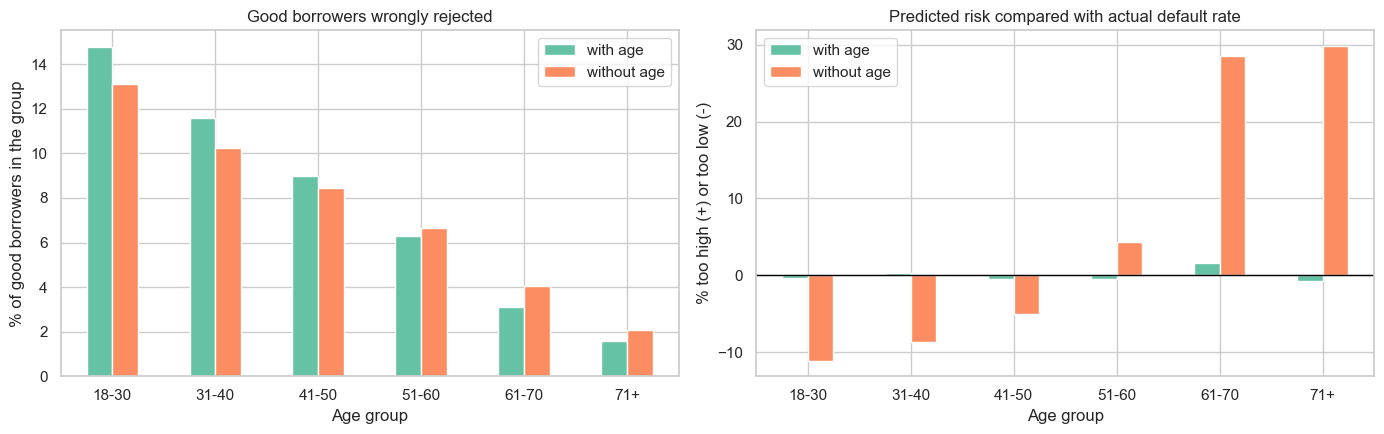

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

pd.DataFrame({"with age": with_age_table["good borrowers rejected"] * 100,
              "without age": without_age_table["good borrowers rejected"] * 100}).plot.bar(ax=axes[0], color=["C0", "C1"])
axes[0].set(title="Good borrowers wrongly rejected", xlabel="Age group", ylabel="% of good borrowers in the group")
axes[0].tick_params(axis="x", rotation=0)

pd.DataFrame({
    "with age": (with_age_table["average predicted risk"] / with_age_table["actual default rate"] - 1) * 100,
    "without age": (without_age_table["average predicted risk"] / without_age_table["actual default rate"] - 1) * 100,
}).plot.bar(ax=axes[1], color=["C0", "C1"])
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(title="Predicted risk compared with actual default rate", xlabel="Age group",
            ylabel="% too high (+) or too low (-)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("../images/fairness_age.png", dpi=120)
plt.show()

Removing age **moves** the burden instead of removing it:

- Young good borrowers are rejected a little less often, but still far more often than older ones.
- Older good borrowers are rejected **more** often than before.
- The model **overestimates** the risk of older applicants by up to about 30%, and underestimates that of younger ones.

In the United States, where age may not count against applicants aged 62 or older, the version *without* age would be the problematic one for older applicants. In a country focused on equal chances for young people, a bank might accept that. The same technical change can be fairer or less fair depending on which rule you apply.

## 8. There is no purely technical answer

What we learned about fairness:

| Approach | What it achieves | What it does not |
|---|---|---|
| **Keep age** | The most accurate model, with honest probabilities for every age group | Young good borrowers are rejected about nine times as often as older ones |
| **Remove age** ("unawareness") | Age itself is no longer used | Other columns still carry age information; older applicants are now overestimated |
| **Other options** (not done here) | Separate thresholds per group, or fairness constraints during training | Each one gives up some accuracy or some other kind of fairness |

What a data scientist **can** do, and what we did:

1. **Measure** how the model treats each group, with several fairness measures, not just one.
2. **Show the trade‑offs** in numbers: here, removing age costs about 0.003 AUC and about \$0.2 million, and shifts errors from young to older applicants.
3. **Document** the choice and the reasons, so that the people who are responsible for it (management, legal, regulators) can decide with full information.

Choosing which kind of fairness matters most is a decision about values and law. It should not be made silently inside a model.

## 9. Conclusions

**What we found**
- The model relies mostly on **behaviour**: credit utilisation and late payments, then age.
- SHAP turns every decision into **plain‑language reasons** for the applicant.
- The model's probabilities are accurate for every age group, yet good young borrowers are rejected about nine times as often as good older ones.
- **Removing age** costs little accuracy (AUC 0.866 → 0.863), but it does not remove the age gap, and it makes the model overestimate older applicants' risk.

**What we learned**

| Concept | In one sentence |
|---|---|
| **Reasons for a decision** | The largest upward SHAP pushes give an applicant the main reasons for a high risk score. |
| **Calibration per group** | The model can be accurate for every group and still treat good borrowers in each group very differently. |
| **Equal error rates** | One fairness measure: good borrowers should have the same chance of being approved in every group. |
| **Fairness through unawareness** | Removing a sensitive column rarely removes its influence, because other columns carry the same information. |
| **Fairness trade‑offs** | Different definitions of fairness cannot all be met at once; the choice must be made and documented by people. |

**The project as a whole**

| Notebook | Main lesson |
|---|---|
| 01 Exploration | Check for copies and strange codes; a column can have two meanings. |
| 02 First model | Cleaning matters for linear models; the threshold is a business decision. |
| 03 Tuning and blending | Near the limit, gains are tiny; compare models fold by fold. |
| 04 Calibration | A great AUC can hide wrong probabilities; class weights distort them. |
| 05 Explanation and fairness | Explain every decision; measure fairness several ways and document the trade‑offs. |